/lustre/work/yaolab/mzhou10/squidiff_practice/Squidiff/project_v3
CUDA Available:  True
Number of GPUs:  1
real_data: View of AnnData object with n_obs × n_vars = 600 × 100
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 100
squidiff_data: AnnData object with n_obs × n_vars = 600 × 100
 squidiff vs new method vs real data cells number: 600 600 600
squidiff method vs real data, gene num 100: P=6.4e-15, D=0.282
new method vs real data, gene num 100: P=2.43e-33, D=0.425
squidiff vs new method, gene num 100: P=5.12e-15, D=0.282
Silhouette squidiff vs real data, gene num 100: 0.0390
Silhouette new method vs real data, gene num 100: 0.0778
Silhouette squidiff vs new method, gene num 100: 0.0468


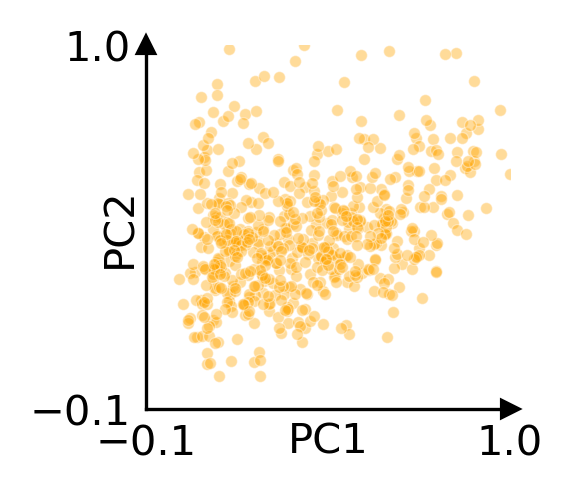

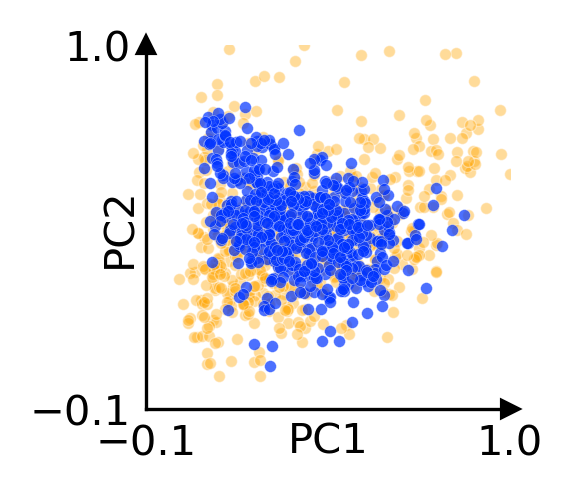

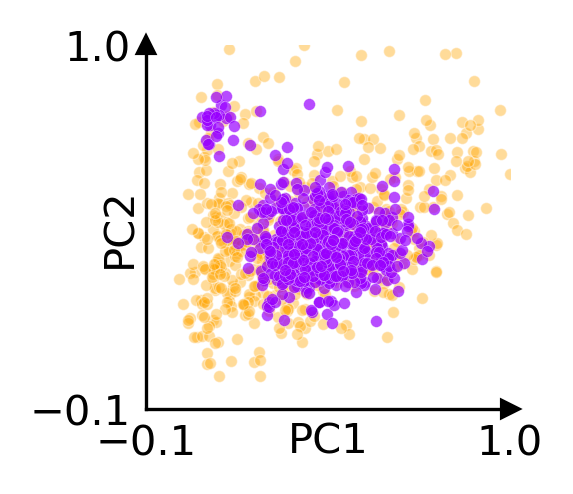

real_data: View of AnnData object with n_obs × n_vars = 600 × 200
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 200
squidiff_data: AnnData object with n_obs × n_vars = 600 × 200
 squidiff vs new method vs real data cells number: 600 600 600
squidiff method vs real data, gene num 200: P=8.7e-14, D=0.268
new method vs real data, gene num 200: P=5.7e-16, D=0.289
squidiff vs new method, gene num 200: P=7.08e-39, D=0.462
Silhouette squidiff vs real data, gene num 200: 0.0435
Silhouette new method vs real data, gene num 200: 0.0325
Silhouette squidiff vs new method, gene num 200: 0.0635


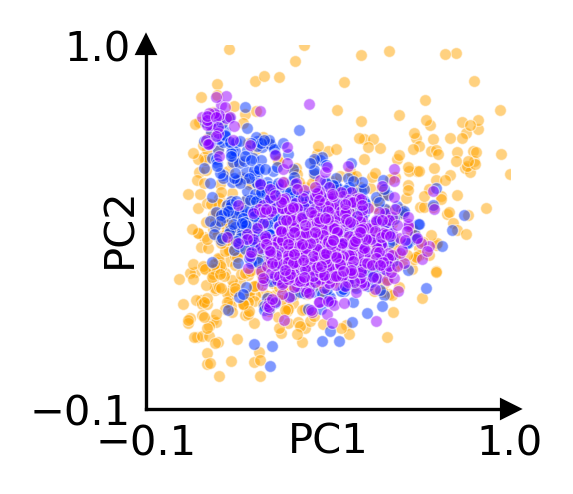

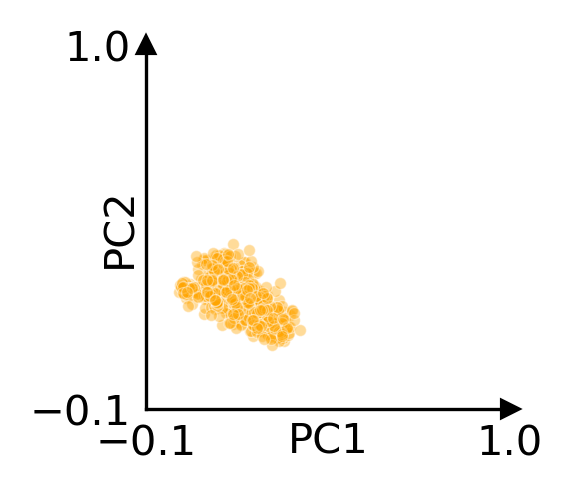

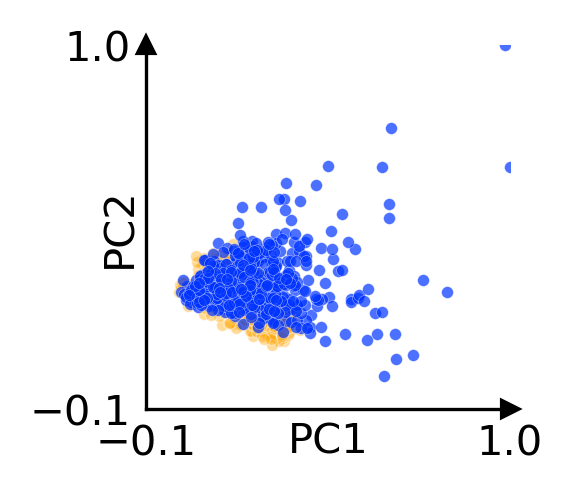

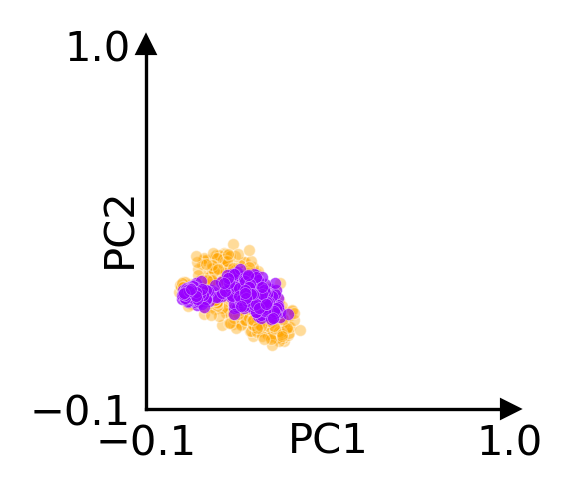

real_data: View of AnnData object with n_obs × n_vars = 600 × 203
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 203
squidiff_data: AnnData object with n_obs × n_vars = 600 × 203
 squidiff vs new method vs real data cells number: 600 600 600
squidiff method vs real data, gene num 203: P=3.34e-27, D=0.379
new method vs real data, gene num 203: P=5.98e-29, D=0.39
squidiff vs new method, gene num 203: P=3.19e-61, D=0.579
Silhouette squidiff vs real data, gene num 203: 0.0841
Silhouette new method vs real data, gene num 203: 0.0627
Silhouette squidiff vs new method, gene num 203: 0.1394


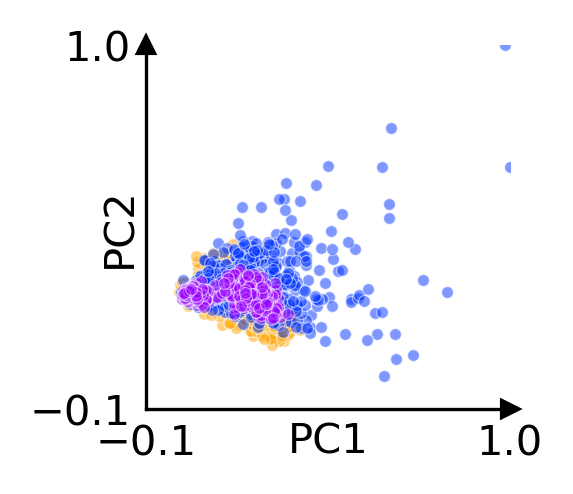

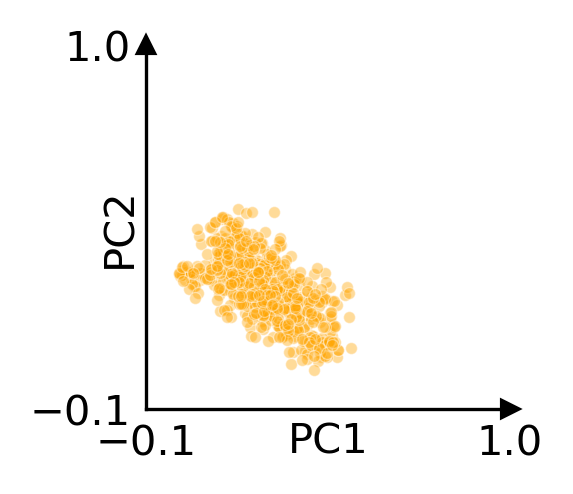

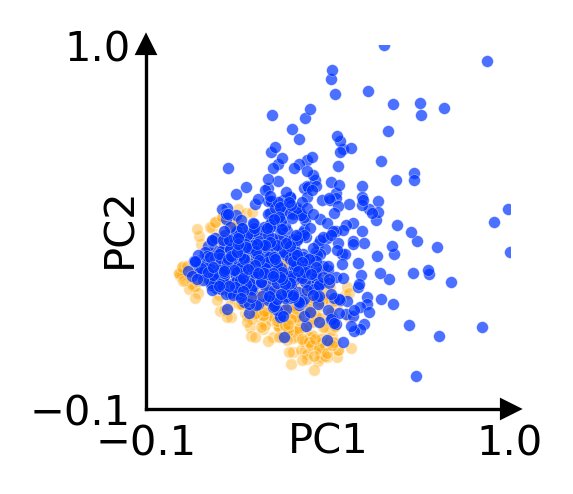

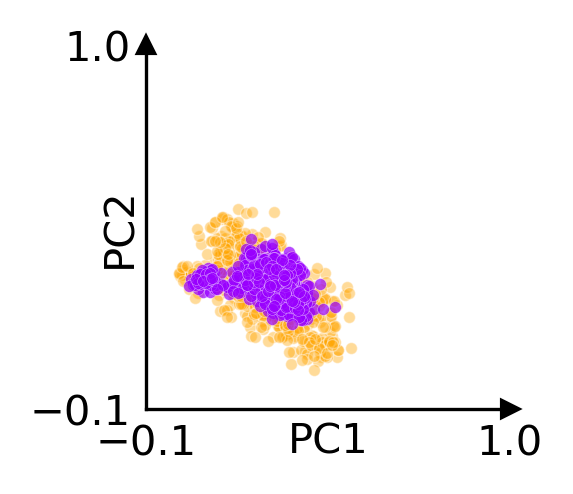

real_data: View of AnnData object with n_obs × n_vars = 600 × 250
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 250
squidiff_data: AnnData object with n_obs × n_vars = 600 × 250
 squidiff vs new method vs real data cells number: 600 600 600
squidiff method vs real data, gene num 250: P=1.78e-153, D=0.907
new method vs real data, gene num 250: P=1.12e-20, D=0.317
squidiff vs new method, gene num 250: P=3.32e-178, D=0.962
Silhouette squidiff vs real data, gene num 250: 0.3959
Silhouette new method vs real data, gene num 250: 0.0426
Silhouette squidiff vs new method, gene num 250: 0.4044


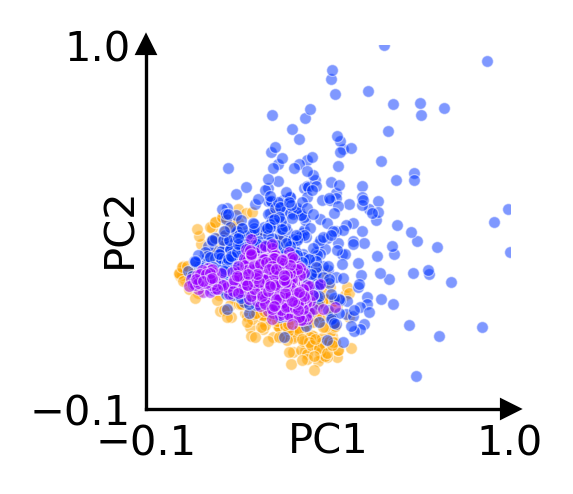

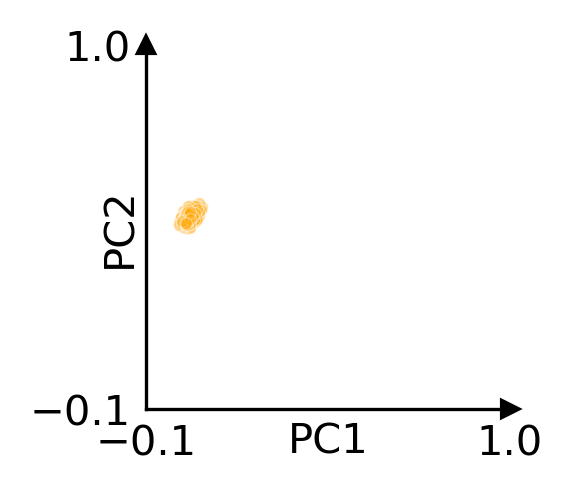

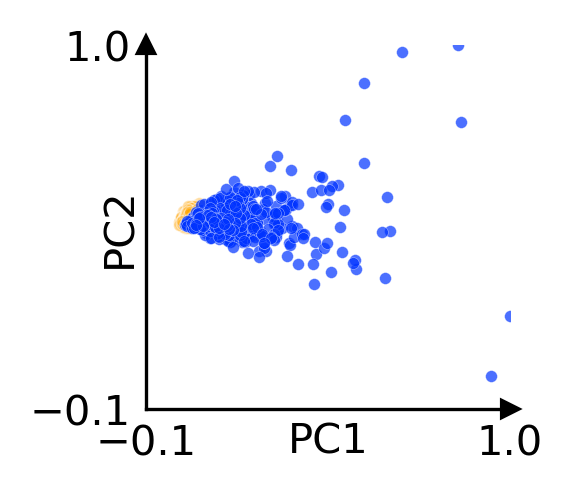

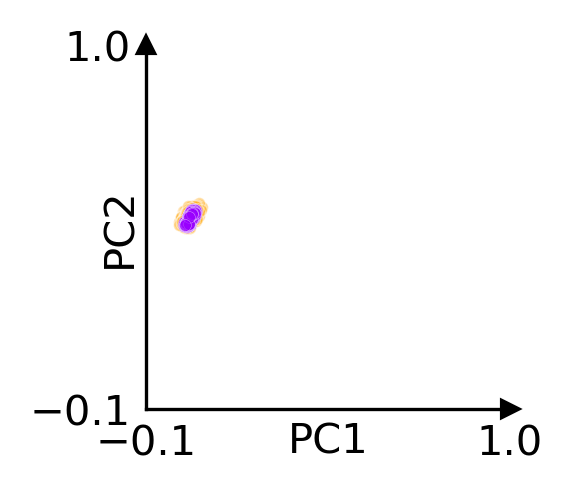

real_data: View of AnnData object with n_obs × n_vars = 600 × 500
    obs: 'Group'
predict_data: AnnData object with n_obs × n_vars = 600 × 500
squidiff_data: AnnData object with n_obs × n_vars = 600 × 500
 squidiff vs new method vs real data cells number: 600 600 600
squidiff method vs real data, gene num 500: P=3.55e-178, D=0.986
new method vs real data, gene num 500: P=2.01e-11, D=0.241
squidiff vs new method, gene num 500: P=5.11e-183, D=0.992
Silhouette squidiff vs real data, gene num 500: 0.7339
Silhouette new method vs real data, gene num 500: 0.0307
Silhouette squidiff vs new method, gene num 500: 0.7353


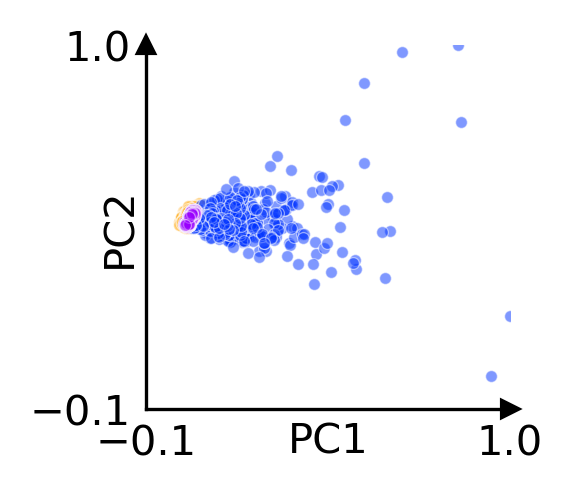

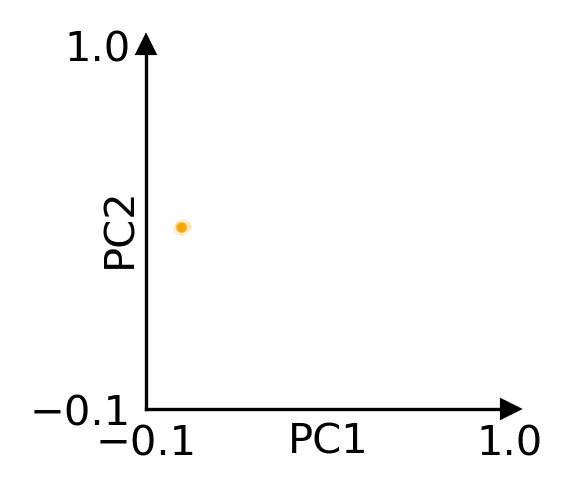

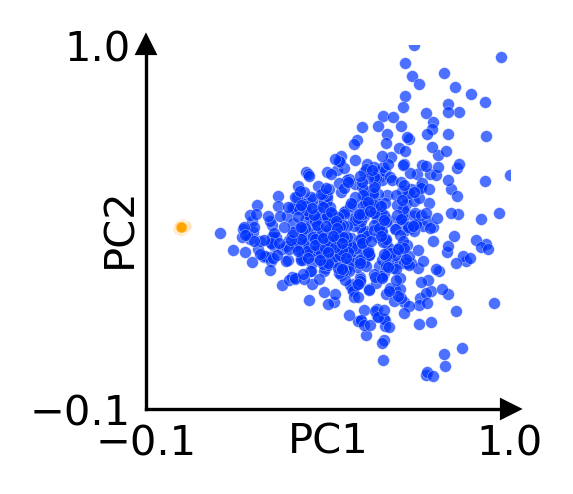

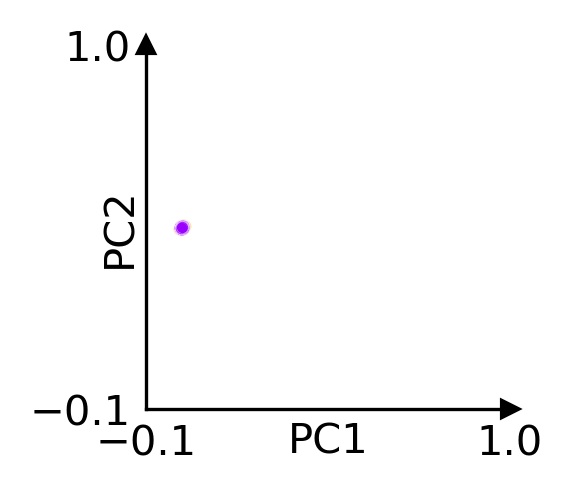

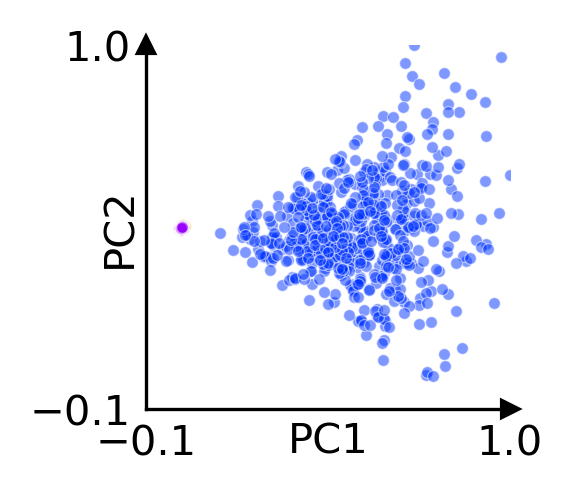

In [1]:
# %load_ext autoreload
# %autoreload 2
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent.parent.parent.parent.parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)

from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson
import scanpy as sc
import os
import anndata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context
import anndata
import seaborn as sns
import torch
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
import scipy.sparse as sp
print("CUDA Available: ", torch.cuda.is_available())
print("Number of GPUs: ", torch.cuda.device_count())
import numpy as np
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import ndtest
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import DistanceMetric

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

# def blur_scatter(bg_x, bg_y, hi_x, hi_y, blur=3):
#     fig, ax = plt.subplots(figsize=(5, 5), dpi=200)

#     # Turn background points into a blurred density image
#     density, x, y = np.histogram2d(bg_x, bg_y, bins=100)
#     ax.imshow(
#         gaussian_filter(density.T, sigma=blur),
#         extent=[x[0], x[-1], y[0], y[-1]],
#         origin="lower", cmap="Greys", aspect="auto", alpha=0.6
#     )

#     # Draw sharp red points
#     ax.scatter(hi_x, hi_y, s=22, c="#e8342c", edgecolors="none")

#     ax.axhline(0, color="black", lw=0.8)
#     ax.axvline(0, color="black", lw=0.8)

#     return fig, ax

def get_pca_2d(x1, x2, x3, num):
    # x1_np = x1.detach().cpu().numpy()
    # x2_np = x2.detach().cpu().numpy()
    x1_np = x1.X if isinstance(x1.X, np.ndarray) else x1.X.toarray()
    x2_np = x2.X if isinstance(x2.X, np.ndarray) else x2.X.toarray()
    x3_np = x3.X if isinstance(x3.X, np.ndarray) else x3.X.toarray()
    
    print(" squidiff vs new method vs real data cells number:", len(x1_np), len(x2_np), len(x3_np))

    X_all = np.vstack([x1_np, x2_np, x3_np])
    
    # Create index array to track source
    index = np.array(['x1'] * len(x1_np) + ['x2'] * len(x2_np) + ['x3'] * len(x3_np))

    pca = PCA(n_components=2)
    X_all_2d_before = pca.fit_transform(X_all)

    scaler = MinMaxScaler()
    X_all_2d = scaler.fit_transform(X_all_2d_before)   # scaled to [0, 1]
    # Separate by index after PCA
    x1_2d = X_all_2d[index == 'x1']#squidiff
    x2_2d = X_all_2d[index == 'x2']
    x3_2d = X_all_2d[index == 'x3']

    # x1_2d: generated cells, shape (n1, 2)
    # x2_2d: real cells, shape (n2, 2)
    x1 = x1_2d[:, 0]  # PC1 of squidiff
    y1 = x1_2d[:, 1]  # PC2 of squidiff

    x2 = x2_2d[:, 0]  # PC1 of new_method
    y2 = x2_2d[:, 1]  # PC2 of new_method

    x3 = x3_2d[:, 0]  # PC1 of real
    y3 = x3_2d[:, 1]  # PC1 of real
    # print("len",len(x1),len(y1),len(x2),len(y2),len(x3),len(y3))
    P, D = ndtest.ks2d2s(x1, y1, x3, y3, extra=True)
    print(f"squidiff method vs real data, gene num {num}: P={P:.3g}, D={D:.3g}")

    P, D = ndtest.ks2d2s(x2, y2, x3, y3, extra=True)
    print(f"new method vs real data, gene num {num}: P={P:.3g}, D={D:.3g}")

    P, D = ndtest.ks2d2s(x1, y1, x2, y2, extra=True)
    print(f"squidiff vs new method, gene num {num}: P={P:.3g}, D={D:.3g}")


    # silhouette: 0 vs 2
    X_s = np.vstack([x1_2d, x3_2d])
    labels_s = np.array([0] * len(x1_2d) + [1] * len(x3_2d))
    sil_s = silhouette_score(X_s, labels_s)
    print(f"Silhouette squidiff vs real data, gene num {num}: {sil_s:.4f}")

    # silhouette: 1 vs 2
    X_n = np.vstack([x2_2d, x3_2d])
    labels_n = np.array([0] * len(x2_2d) + [1] * len(x3_2d))
    sil_n = silhouette_score(X_n, labels_n)
    print(f"Silhouette new method vs real data, gene num {num}: {sil_n:.4f}")

    X_n = np.vstack([x1_2d, x2_2d])
    labels_n = np.array([0] * len(x1_2d) + [1] * len(x2_2d))
    sil_n = silhouette_score(X_n, labels_n)
    print(f"Silhouette squidiff vs new method, gene num {num}: {sil_n:.4f}")

    #example 1
#     max_abs_x = max(np.abs(x1).max(), np.abs(x2).max(),np.abs(x3).max())
#     min_abs_x = min(np.abs(x1).min(), np.abs(x2).min(),np.abs(x3).min())
#     max_abs_y = max(np.abs(y1).max(),np.abs(y2).max(), np.abs(y3).max())
#     min_abs_y = min(np.abs(y1).min(), np.abs(y2).min(),np.abs(y3).min())

    # plt.figure(figsize=(2, 2), dpi=300)
    fig, ax = plt.subplots(figsize=(2, 2), dpi=300)
#     xlim = (min_abs_x-0.2, max_abs_x)
#     ylim = (min_abs_y-0.2, max_abs_y)
    ax.scatter(x3, y3, s=8, c="orange", alpha=0.4, edgecolors="white", linewidths=0.3, zorder=1, label='real data')
#     ax.scatter(x1, y1, s=8, c="#0033FF", alpha=0.7, edgecolors="white", linewidths=0.1,zorder=2, label="Squidiff")
    ax.set_xlim(-0.1, 1)
    ax.set_ylim(-0.1, 1)
    # Only show endpoint numbers
    ax.set_xticks([-0.1, 1])
    ax.set_yticks([-0.1, 1])
    # ax.set_yticklabels(["-0.1", "1"])
    # Keep bottom and left borders
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_visible(True)
    ax.spines["left"].set_visible(True)
    ax.tick_params(axis="both", which="both", length=0)
    # Arrowheads at the ends of the axes
    ax.plot(1, -0.1, marker=">", color="black", markersize=4,
            transform=ax.get_yaxis_transform(), clip_on=False)
    ax.plot(-0.1, 1, marker="^", color="black", markersize=4,
            transform=ax.get_xaxis_transform(), clip_on=False)
    ax.set_aspect("equal", adjustable="box")
    plt.xlabel("PC1", labelpad=-10)
    plt.ylabel("PC2", labelpad=-26.5)
    plt.tight_layout()
    plt.savefig(f"ks_pca_compare_gene_num_{num}_ground_truth.pdf", bbox_inches="tight")
    plt.show()



    max_abs_x = max(np.abs(x1).max(), np.abs(x2).max(),np.abs(x3).max())
    min_abs_x = min(np.abs(x1).min(), np.abs(x2).min(),np.abs(x3).min())
    max_abs_y = max(np.abs(y1).max(),np.abs(y2).max(), np.abs(y3).max())
    min_abs_y = min(np.abs(y1).min(), np.abs(y2).min(),np.abs(y3).min())

    # plt.figure(figsize=(2, 2), dpi=300)
    fig, ax = plt.subplots(figsize=(2, 2), dpi=300)
    # plt.scatter(x1, y1, s=2, alpha=1, c='blue', label='squidiff',edgecolors='none')
    # plt.scatter(x2, y2, s=10, alpha=1, c='red', label='new method',edgecolors='none')
    # plt.scatter(x3, y3, s=10, c="yellow", alpha=0.3, linewidths=0,label='real data')
 
    xlim = (min_abs_x-0.2, max_abs_x)
    ylim = (min_abs_y-0.2, max_abs_y)
    #     sns.scatterplot(
    #     x=x3, y=y3,
    #     s=5, color="gray", alpha=0.2,
    #     edgecolor="white", linewidth=0.1,
    #     ax=ax, zorder=1, label="real data",
    # )
    #     sns.scatterplot(
    #     x=x1, y=y1,
    #     s=5, color="#0033FF", alpha=0.9,
    #     edgecolor="white", linewidth=0.1,
    #     ax=ax, zorder=1, label="squidiff",
    # )
    ax.scatter(x3, y3, s=8, c="orange", alpha=0.4, edgecolors="white", linewidths=0.3, zorder=1, label='real data')
    ax.scatter(x1, y1, s=8, c="#0033FF", alpha=0.7, edgecolors="white", linewidths=0.1,zorder=2, label="Squidiff")
    # plt.xlim(*xlim)
    # plt.ylim(*ylim)
    # ax.set_xlim(*xlim)
    # ax.set_ylim(*ylim)
    # ax.tick_params(labelsize=8, length=0)
    # for spine in ax.spines.values():
    #     spine.set_color("#888888")
    #     spine.set_linewidth(0.8)
    # ax.set_aspect("equal", adjustable="box")
    # ax.set_xticks([round(min_abs_x-0.2,1),max_abs_x])
    # ax.set_yticks([round(min_abs_x-0.2,1),max_abs_y])
    # plt.xlabel("PC1")
    # plt.ylabel("PC2")
    # plt.title(f"PCA of cells\n2D KS")
    # plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
    ax.set_xlim(-0.1, 1)
    ax.set_ylim(-0.1, 1)
    # Only show endpoint numbers
    ax.set_xticks([-0.1, 1])
    ax.set_yticks([-0.1, 1])
    # ax.set_yticklabels(["-0.1", "1"])
    # Keep bottom and left borders
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_visible(True)
    ax.spines["left"].set_visible(True)

    # ax.tick_params(top=False, right=False)
    # ax.grid(False)
    ax.tick_params(axis="both", which="both", length=0)
    # Arrowheads at the ends of the axes
    ax.plot(1, -0.1, marker=">", color="black", markersize=4,
            transform=ax.get_yaxis_transform(), clip_on=False)
    ax.plot(-0.1, 1, marker="^", color="black", markersize=4,
            transform=ax.get_xaxis_transform(), clip_on=False)
    ax.set_aspect("equal", adjustable="box")
    plt.xlabel("PC1", labelpad=-10)
    plt.ylabel("PC2", labelpad=-26.5)
    plt.tight_layout()
    plt.savefig(f"ks_pca_compare_gene_num_{num}_squidiff.pdf", bbox_inches="tight")
    plt.show()
    fig, ax = plt.subplots(figsize=(2, 2), dpi=300)
    ax.scatter(x3, y3, s=8, c="orange", alpha=0.4, edgecolors="white", linewidths=0.3, zorder=1, label='real data')
    ax.scatter(x2, y2, s=8, c="#9900FF", alpha=0.7, edgecolors="white", linewidths=0.1, zorder=2, label="new method")
    # ax.set_xlim(*xlim)
    # ax.set_ylim(*ylim)
    # ax.set_aspect("equal", adjustable="box")
    # ax.set_xticks([round(min_abs_x-0.2,1),max_abs_x])
    # ax.set_yticks([round(min_abs_x-0.2,1),max_abs_y])
    # ax.tick_params(labelsize=8, length=0)
    # for spine in ax.spines.values():
    #     spine.set_color("#888888")
    #     spine.set_linewidth(0.8)
    # plt.xlabel("PC1")
    # plt.ylabel("PC2")
    # plt.title(f"PCA of cells\n2D KS")
    # plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
    ax.set_xlim(-0.1, 1)
    ax.set_ylim(-0.1, 1)
    # Only show endpoint numbers
    ax.set_xticks([-0.1, 1])
    ax.set_yticks([-0.1, 1])
    # ax.set_yticklabels(["-0.1", "1"])
    # ax.set_xticklabels(["-0.1", "1"])
    # Keep bottom and left borders
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_visible(True)
    ax.spines["left"].set_visible(True)

    # ax.tick_params(top=False, right=False)
    # ax.grid(False)
    ax.tick_params(axis="both", which="both", length=0)
    # Arrowheads at the ends of the axes
    ax.plot(1, -0.1, marker=">", color="black", markersize=4,
            transform=ax.get_yaxis_transform(), clip_on=False)
    ax.plot(-0.1, 1, marker="^", color="black", markersize=4,
            transform=ax.get_xaxis_transform(), clip_on=False)
    ax.set_aspect("equal", adjustable="box")
    plt.xlabel("PC1", labelpad=-10)
    plt.ylabel("PC2", labelpad=-26.5)
    plt.tight_layout()
    plt.savefig(f"ks_pca_compare_gene_num_{num}_celldiffgen.pdf", bbox_inches="tight")
    plt.show()


    fig, ax = plt.subplots(figsize=(2, 2), dpi=300)
    # ax.scatter(x3, y3, s=1, color="#66FF66", alpha=0.55, linewidths=0, zorder=2)
    ax.scatter(x3, y3, s=8, c="orange", alpha=0.5, edgecolors="white", linewidths=0.3, zorder=1, label='real data')
    ax.scatter(x1, y1, s=8, c="#0033FF", alpha=0.5, edgecolors="white", linewidths=0.3,zorder=2, label="squidiff")
    ax.scatter(x2, y2, s=8, c="#9900FF", alpha=0.5, edgecolors="white", linewidths=0.3, zorder=2, label="new method")
    # ax.set_aspect("equal", adjustable="box")
    # ax.tick_params(labelsize=8, length=0)
    # for spine in ax.spines.values():
    #     spine.set_color("#888888")
    #     spine.set_linewidth(0.8)
    # ax.set_xlim(*xlim)
    # ax.set_ylim(*ylim)
    # ax.set_xticks([round(min_abs_x-0.2,1),max_abs_x])
    # ax.set_yticks([round(min_abs_x-0.2,1),max_abs_y])
    # plt.xlabel("PC1")
    # plt.ylabel("PC2")
    # plt.title(f"PCA of cells\n2D KS")
    ax.set_xlim(-0.1, 1)
    ax.set_ylim(-0.1, 1)
    # Only show endpoint numbers
    ax.set_xticks([-0.1, 1])
    ax.set_yticks([-0.1, 1])
    # ax.set_yticklabels(["-0.1", "1"])
    # Keep bottom and left borders
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_visible(True)
    ax.spines["left"].set_visible(True)

    # ax.tick_params(top=False, right=False)
    # ax.grid(False)
    ax.tick_params(axis="both", which="both", length=0)
    # Arrowheads at the ends of the axes
    ax.plot(1, -0.1, marker=">", color="black", markersize=4,
            transform=ax.get_yaxis_transform(), clip_on=False)
    ax.plot(-0.1, 1, marker="^", color="black", markersize=4,
            transform=ax.get_xaxis_transform(), clip_on=False)
    plt.xlabel("PC1", labelpad=-10)
    plt.ylabel("PC2", labelpad=-26.5)
    ax.set_aspect("equal", adjustable="box")
    plt.tight_layout()
    plt.savefig(f"cluster_simple_{num}.pdf", bbox_inches="tight")


# for i in [100,200,203,250,300,400,500,1000,5000]:
# for i in [1000]:
for i in [100,200,203,250,500]:
    real_data_origin = sc.read_h5ad(f"../../input/diff_test_gene_num_{i}.h5ad")
    real_adata = real_data_origin[real_data_origin.obs['Group']==3]
    # real_data = sc.read_h5ad("../../input/test_day0_data.h5ad")
    print("real_data:",real_adata)

    predict_data = sc.read_h5ad(f"../experiments/exp5_day0_predict_day3_gene_num_{i}/interception_predict_to_day_3.h5ad")
    print("predict_data:",predict_data)
    squidiff_data = sc.read_h5ad(f"../../squidiff/experiments/squidiff_exp5_extend_day0_predict_day3_gene_num_{i}.h5ad")
    print("squidiff_data:",squidiff_data)
    # get_pairwase_2d(squidiff_data,predict_data, real_adata,i)
    get_pca_2d(squidiff_data, predict_data, real_adata,i)